# Laboratório de Ciência de Dados aplicado ao Jornalismo Esportivo
### Avaliação de Segunda Chamada — CEUB

| Campo | Informação |
|---|---|
| Disciplina | Jornalismo Esportivo |
| Professora | Kadidja Valéria |
| Ferramenta | Google Colab e Python |
| Estudante | _________________________ |

**Pergunta-guia:** quais características dos conteúdos esportivos estão associadas ao maior **alcance, engajamento, retenção, geração de cliques e conversão de assinantes**?

**Perspectiva adotada:** análise de dados com olhar de marketing de conteúdo (funil *alcance → engajamento → recirculação → assinatura/receita*), sem abrir mão dos critérios jornalísticos de relevância, interesse público, diversidade, precisão e responsabilidade.

**Perguntas que orientam o trabalho (etapa de compreensão):**
1. O conteúdo mais visto é também o que mais engaja, retém e converte?
2. Modalidade, formato, turno e canal mudam o desempenho?
3. Que decisões de pauta, formato e distribuição os dados realmente sustentam — e quais são só hipóteses?

**Sumário:** 1 Diagnóstico · 2 Tratamento · 3 Métricas · 4 Agrupamentos · 5 Visualizações · 6 Questões 1 a 8 · 7 Conclusão e limitações · 8 Discussão de fechamento

## Etapa 1 — Carregamento e diagnóstico

In [1]:
# ---------- Bibliotecas e configurações gerais ----------
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")                 # deixa a saída do notebook mais limpa
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Paleta fixa para manter a mesma cor para a mesma categoria em todos os gráficos
CORES_MOD  = {"Futebol": "#4B0A4F", "Basquete": "#8E44AD", "Vôlei": "#D6007E", "Automobilismo": "#2A9D8F"}
CORES_TIPO = {"Notícia": "#6C757D", "Análise": "#8E44AD", "Entrevista": "#D6007E",
              "Reportagem": "#4B0A4F", "Vídeo": "#2A9D8F"}

def br(x, casas=2):
    """Formata número no padrão brasileiro (1.234,56)."""
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [2]:
# ---------- Carregamento do CSV ----------
ARQUIVO = "dataset_jornalismo_esportivo_segunda_chamada.csv"

# No Google Colab, se o arquivo ainda não estiver na sessão, pede o upload
if not os.path.exists(ARQUIVO):
    try:
        from google.colab import files
        print("Selecione o arquivo CSV para upload:")
        enviado = files.upload()
        ARQUIVO = list(enviado.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Coloque '{ARQUIVO}' na mesma pasta do notebook.")

df = pd.read_csv(ARQUIVO)

# Preserva uma cópia intocada da base original (exigência da avaliação)
df_original = df.copy()

print("=== Cinco primeiras linhas ===")
display(df.head())

print("\n=== Dimensões (linhas, colunas) ===")
print(df.shape)

print("\n=== Tipos das colunas e não-nulos ===")
df.info()

print("\n=== Valores ausentes por coluna ===")
print(df.isna().sum())

print("\nRegistros duplicados:", df.duplicated().sum())

=== Cinco primeiras linhas ===


,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.0,1200,180,310,4100,145,4300
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.0,720,140,260,2300,92,2500
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.0,980,195,410,1900,105,2300
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.0,650,120,300,2500,120,3800
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.0,2600,350,620,5300,190,5200



=== Dimensões (linhas, colunas) ===
(24, 15)

=== Tipos das colunas e não-nulos ===
<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   data_publicacao       24 non-null     str    
 1   portal                24 non-null     str    
 2   titulo                24 non-null     str    
 3   modalidade            24 non-null     str    
 4   tipo_conteudo         24 non-null     str    
 5   turno_publicacao      24 non-null     str    
 6   visualizacoes         24 non-null     int64  
 7   usuarios_unicos       24 non-null     int64  
 8   tempo_medio_segundos  23 non-null     float64
 9   curtidas              24 non-null     int64  
 10  comentarios           24 non-null     int64  
 11  compartilhamentos     24 non-null     int64  
 12  cliques_relacionados  24 non-null     int64  
 13  novos_assinantes      24 non-null     int64  
 14  re

In [3]:
# ---------- Classificação das variáveis ----------
colunas_temporais   = ["data_publicacao"]
colunas_categoricas = ["portal", "titulo", "modalidade", "tipo_conteudo", "turno_publicacao"]
colunas_numericas   = [c for c in df.columns if c not in colunas_temporais + colunas_categoricas]

print("Temporais   :", colunas_temporais)
print("Categóricas :", colunas_categoricas)
print("Numéricas   :", colunas_numericas)

# ---------- Categorias inconsistentes: mostra o valor "cru" (repr) para revelar espaços escondidos ----------
print("\n=== Categorias existentes (repr revela espaços extras) ===")
for col in ["portal", "modalidade", "tipo_conteudo", "turno_publicacao"]:
    print(f"{col:18s}", [repr(v) for v in sorted(df[col].unique())])

# Conta quantos registros têm espaço no início/fim em cada coluna de texto
print("\n=== Registros com espaços extras ===")
for col in ["portal", "titulo", "modalidade", "tipo_conteudo", "turno_publicacao"]:
    print(f"{col:18s}", int((df[col] != df[col].str.strip()).sum()))

# ---------- Regras de coerência entre variáveis ----------
print("\n=== Checagens de coerência ===")
print("usuários únicos > visualizações      :", int((df["usuarios_unicos"] > df["visualizacoes"]).sum()))
print("novos assinantes > cliques relac.    :", int((df["novos_assinantes"] > df["cliques_relacionados"]).sum()))
print("valores negativos nas numéricas      :", int((df[colunas_numericas] < 0).sum().sum()))
print("denominadores iguais a zero          :", int((df[["visualizacoes", "usuarios_unicos", "cliques_relacionados"]] == 0).sum().sum()))
print("títulos repetidos                    :", int(df["titulo"].duplicated().sum()))

# ---------- O registro com valor ausente ----------
print("\n=== Registro(s) com valor ausente ===")
display(df[df.isna().any(axis=1)])

print("\n=== Estatísticas descritivas das numéricas ===")
display(df[colunas_numericas].describe().T.round(1))

Temporais   : ['data_publicacao']
Categóricas : ['portal', 'titulo', 'modalidade', 'tipo_conteudo', 'turno_publicacao']
Numéricas   : ['visualizacoes', 'usuarios_unicos', 'tempo_medio_segundos', 'curtidas', 'comentarios', 'compartilhamentos', 'cliques_relacionados', 'novos_assinantes', 'receita_publicitaria']

=== Categorias existentes (repr revela espaços extras) ===
portal             ["'Instagram'", "'Newsletter'", "'Site'", "'YouTube'"]
modalidade         ["'Automobilismo'", "'Basquete'", "'Futebol'", "'Vôlei'", "'Vôlei '"]
tipo_conteudo      ["'Análise'", "'Entrevista'", "'Notícia'", "'Reportagem'", "'Vídeo'"]
turno_publicacao   ["'Manhã'", "'Noite'", "'Tarde'"]

=== Registros com espaços extras ===
portal             0
titulo             0
modalidade         1
tipo_conteudo      0
turno_publicacao   0

=== Checagens de coerência ===
usuários únicos > visualizações      : 0
novos assinantes > cliques relac.    : 0
valores negativos nas numéricas      : 0
denominadores iguais a zer

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
19,2026-10-17,YouTube,Piloto comenta disputa pelo pódio,Automobilismo,Entrevista,Noite,23000,18500,NaN,820,145,350,2600,130,3900



=== Estatísticas descritivas das numéricas ===


,count,mean,std,min,25%,50%,75%,max
visualizacoes,24.0,32062.5,15148.8,16000.0,22750.0,27000.0,35250.0,75000.0
usuarios_unicos,24.0,26137.5,12730.5,12800.0,18500.0,22000.0,28500.0,64000.0
tempo_medio_segundos,23.0,189.5,77.6,62.0,122.5,210.0,247.5,310.0
curtidas,24.0,1143.3,623.9,480.0,775.0,950.0,1237.5,3100.0
comentarios,24.0,195.2,81.6,80.0,143.8,175.0,222.5,410.0
compartilhamentos,24.0,422.5,149.5,210.0,317.5,400.0,502.5,750.0
cliques_relacionados,24.0,2885.4,949.5,1700.0,2187.5,2600.0,3200.0,5300.0
novos_assinantes,24.0,128.2,30.2,70.0,107.2,125.5,145.0,190.0
receita_publicitaria,24.0,3475.0,917.6,2000.0,2600.0,3400.0,4225.0,5200.0


### Questão 1 — Diagnóstico dos dados

**a) Registros e variáveis:** a base tem **24 registros (publicações) e 15 variáveis**.

**b) Tipos de coluna**
- **Temporal:** `data_publicacao` (chega como texto e é convertida para data na Etapa 2).
- **Categóricas:** `portal`, `titulo`, `modalidade`, `tipo_conteudo`, `turno_publicacao` (`titulo` funciona como identificador textual).
- **Numéricas:** `visualizacoes`, `usuarios_unicos`, `tempo_medio_segundos`, `curtidas`, `comentarios`, `compartilhamentos`, `cliques_relacionados`, `novos_assinantes`, `receita_publicitaria`.

**c) Problemas de qualidade encontrados**
1. **Valor ausente:** 1 registro sem `tempo_medio_segundos` (a entrevista *"Piloto comenta disputa pelo pódio"*, Automobilismo, YouTube, 17/10).
2. **Categoria inconsistente:** 1 registro(s) com `"Vôlei "` (espaço no fim), que faria o pandas tratar a modalidade como **duas categorias diferentes**.
3. Não há duplicados, valores negativos, `usuarios_unicos` maior que `visualizacoes` nem assinantes maiores que cliques — a base é coerente nesses pontos.

**d) Por que não substituir o ausente por zero?** Zero é uma **medição** ("os leitores ficaram 0 segundo"), enquanto o dado ausente é **falta de informação**. Na prática, essa lacuna provavelmente vem de falha de exportação/rastreamento da plataforma (um vídeo/entrevista no YouTube, cuja métrica de retenção vem de outra ferramenta). Preencher com 0 puxaria a média do formato para baixo e poderia **trocar o ranking** — isso é demonstrado numericamente na Etapa 2.

## Etapa 2 — Tratamento

In [4]:
# Trabalhamos numa cópia ("dados"); a base original continua preservada em df_original
dados = df.copy()

# 1) Remove espaços extras da modalidade ("Vôlei " -> "Vôlei")
dados["modalidade"] = dados["modalidade"].str.strip()

# 2) Converte a data de texto para datetime; datas inválidas viram NaT (errors="coerce")
dados["data_publicacao"] = pd.to_datetime(dados["data_publicacao"], errors="coerce")

# ---------- Verificação do tratamento ----------
print("Modalidades após o tratamento:")
print(dados["modalidade"].value_counts())
print("\nDatas inválidas:", dados["data_publicacao"].isna().sum())
print("Período:", dados["data_publicacao"].min().date(), "a", dados["data_publicacao"].max().date())
print("Datas distintas:", dados["data_publicacao"].nunique())
print("Tipo da coluna de data:", dados["data_publicacao"].dtype)

Modalidades após o tratamento:
modalidade
Futebol          6
Basquete         6
Vôlei            6
Automobilismo    6
Name: count, dtype: int64

Datas inválidas: 0
Período: 2026-10-01 a 2026-10-21
Datas distintas: 6
Tipo da coluna de data: datetime64[us]


In [5]:
# ---------- Por que NÃO preencher o ausente com zero? Teste de sensibilidade ----------
# Cenário A: ignora o ausente (padrão do pandas na média)
tempo_ignora = dados.groupby("tipo_conteudo")["tempo_medio_segundos"].mean()

# Cenário B: (INCORRETO) preenche com zero
tempo_zero = dados.assign(tempo_medio_segundos=dados["tempo_medio_segundos"].fillna(0)) \
                  .groupby("tipo_conteudo")["tempo_medio_segundos"].mean()

sens = pd.DataFrame({"ignorando_ausente": tempo_ignora, "ausente_vira_zero": tempo_zero}).round(1)
sens["diferenca"] = (sens["ausente_vira_zero"] - sens["ignorando_ausente"]).round(1)
print("Tempo médio (s) por tipo de conteúdo:")
display(sens.sort_values("ignorando_ausente", ascending=False))

print("\nMaior tempo médio ignorando o ausente :", tempo_ignora.idxmax())
print("Maior tempo médio com o ausente = zero:", tempo_zero.idxmax())

Tempo médio (s) por tipo de conteúdo:


,ignorando_ausente,ausente_vira_zero,diferenca
tipo_conteudo,,,
Entrevista,273.3,205.0,-68.3
Vídeo,251.2,251.2,0.0
Reportagem,237.0,237.0,0.0
Análise,176.0,176.0,0.0
Notícia,78.0,78.0,0.0



Maior tempo médio ignorando o ausente : Entrevista
Maior tempo médio com o ausente = zero: Vídeo


**Registro da ausência (origem e consequência)**
- **Possível origem:** falha na coleta/exportação do tempo de permanência de uma entrevista publicada no YouTube; não há evidência de que o tempo tenha sido zero.
- **Consequência:** o formato *Entrevista* tem 4 publicações, mas só **3 com tempo médio**; qualquer média desse formato é menos confiável. Se o ausente virasse zero, a média de Entrevista cairia de ~273 s para 205 s e **Vídeo (251 s) assumiria a liderança** — uma conclusão editorial diferente criada só por um preenchimento artificial.
- **Decisão:** o valor foi **mantido como ausente (NaN)**; as médias ignoram o registro e a limitação é declarada nas análises de tempo.

## Etapa 3 — Cálculo das métricas

| Métrica | Fórmula |
|---|---|
| Taxa de engajamento | (curtidas + comentários + compartilhamentos) ÷ visualizações × 100 |
| Taxa de recirculação | cliques relacionados ÷ visualizações × 100 |
| Taxa de conversão | novos assinantes ÷ cliques relacionados × 100 |
| RPM | receita publicitária ÷ visualizações × 1.000 |
| Frequência média | visualizações ÷ usuários únicos |

Acrescentei uma métrica de apoio de marketing, **assinantes por mil visualizações** (novos assinantes ÷ visualizações × 1.000), porque a taxa de conversão do roteiro usa *cliques relacionados* como base e não mede diretamente o quanto o **alcance** vira assinatura.

In [6]:
def div_segura(numerador, denominador, fator=1):
    """Divisão que devolve NaN (e não infinito) quando o denominador é zero."""
    denominador = denominador.replace(0, np.nan)
    return (numerador / denominador) * fator

# Total de interações = tudo que o leitor "faz" com o conteúdo além de ler
dados["total_interacoes"] = dados["curtidas"] + dados["comentarios"] + dados["compartilhamentos"]

dados["taxa_engajamento_pct"]  = div_segura(dados["total_interacoes"],      dados["visualizacoes"],        100)
dados["taxa_recirculacao_pct"] = div_segura(dados["cliques_relacionados"],  dados["visualizacoes"],        100)
dados["taxa_conversao_pct"]    = div_segura(dados["novos_assinantes"],      dados["cliques_relacionados"], 100)
dados["rpm"]                   = div_segura(dados["receita_publicitaria"],  dados["visualizacoes"],        1000)
dados["frequencia_media"]      = div_segura(dados["visualizacoes"],         dados["usuarios_unicos"])
# Métrica de apoio (marketing): quantas assinaturas cada mil visualizações geram
dados["assinantes_por_mil_views"] = div_segura(dados["novos_assinantes"],   dados["visualizacoes"],        1000)

# Garante que nenhuma divisão gerou infinito
metricas = ["taxa_engajamento_pct", "taxa_recirculacao_pct", "taxa_conversao_pct", "rpm",
            "frequencia_media", "assinantes_por_mil_views"]
print("Valores infinitos:", int(np.isinf(dados[metricas]).sum().sum()))

display(dados[["titulo", "modalidade", "tipo_conteudo", "portal"] + metricas].round(2))

# Salva a base tratada (produto final)
dados.to_csv("base_tratada.csv", index=False)

Valores infinitos: 0


,titulo,modalidade,tipo_conteudo,portal,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,assinantes_por_mil_views
0,Clássico nacional movimenta a rodada,Futebol,Notícia,Site,3.25,7.88,3.54,82.69,1.21,2.79
1,Como o basquete mudou sua defesa,Basquete,Análise,Site,4.00,8.21,4.00,89.29,1.24,3.29
2,Capitã fala sobre preparação para a final,Vôlei,Entrevista,YouTube,8.81,10.56,5.53,127.78,1.24,5.83
3,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Site,4.46,10.42,4.80,158.33,1.23,5.00
4,Os melhores lances do fim de semana,Futebol,Vídeo,YouTube,5.25,7.79,3.58,76.47,1.24,2.79
5,Time confirma reforço para a temporada,Basquete,Notícia,Site,3.73,6.77,3.33,70.97,1.22,2.26
6,O saque que decidiu as últimas partidas,Vôlei,Análise,Site,7.84,10.62,5.29,125.00,1.25,5.62
7,Volta rápida comentada por especialista,Automobilismo,Vídeo,YouTube,5.03,10.34,4.83,151.72,1.23,5.00
8,Pressão alta explica vitória no clássico,Futebol,Análise,Site,3.74,9.07,4.49,95.35,1.23,4.07
9,Armador revela rotina de treinamento,Basquete,Entrevista,YouTube,6.23,9.23,4.79,119.23,1.24,4.42


### Questão 2 — Métricas do primeiro conteúdo

In [7]:
# Primeiro conteúdo da base (linha 0)
p = dados.iloc[0]
print("Conteúdo:", p["titulo"], f"| {p['modalidade']} | {p['tipo_conteudo']} | {p['portal']} | {p['turno_publicacao']}")
print("-" * 95)

# Médias do portal (somando numeradores e denominadores) para comparação
tot = dados[["total_interacoes", "visualizacoes", "cliques_relacionados", "novos_assinantes",
             "receita_publicitaria", "usuarios_unicos"]].sum()
ref = {
    "eng":  tot["total_interacoes"] / tot["visualizacoes"] * 100,
    "rec":  tot["cliques_relacionados"] / tot["visualizacoes"] * 100,
    "conv": tot["novos_assinantes"] / tot["cliques_relacionados"] * 100,
    "rpm":  tot["receita_publicitaria"] / tot["visualizacoes"] * 1000,
    "freq": tot["visualizacoes"] / tot["usuarios_unicos"],
}

print(f"1) Taxa de engajamento = (curtidas + comentários + compartilhamentos) ÷ visualizações × 100")
print(f"   = ({p['curtidas']} + {p['comentarios']} + {p['compartilhamentos']}) ÷ {p['visualizacoes']} × 100 = {br(p['taxa_engajamento_pct'])}%   (portal: {br(ref['eng'])}%)\n")
print(f"2) Taxa de recirculação = cliques relacionados ÷ visualizações × 100")
print(f"   = {p['cliques_relacionados']} ÷ {p['visualizacoes']} × 100 = {br(p['taxa_recirculacao_pct'])}%   (portal: {br(ref['rec'])}%)\n")
print(f"3) Taxa de conversão = novos assinantes ÷ cliques relacionados × 100")
print(f"   = {p['novos_assinantes']} ÷ {p['cliques_relacionados']} × 100 = {br(p['taxa_conversao_pct'])}%   (portal: {br(ref['conv'])}%)\n")
print(f"4) RPM = receita publicitária ÷ visualizações × 1.000")
print(f"   = {p['receita_publicitaria']} ÷ {p['visualizacoes']} × 1.000 = {br(p['rpm'])}   (portal: {br(ref['rpm'])})\n")
print(f"5) Frequência média = visualizações ÷ usuários únicos")
print(f"   = {p['visualizacoes']} ÷ {p['usuarios_unicos']} = {br(p['frequencia_media'])}   (portal: {br(ref['freq'])})")

Conteúdo: Clássico nacional movimenta a rodada | Futebol | Notícia | Site | Manhã
-----------------------------------------------------------------------------------------------
1) Taxa de engajamento = (curtidas + comentários + compartilhamentos) ÷ visualizações × 100
   = (1200 + 180 + 310) ÷ 52000 × 100 = 3,25%   (portal: 5,49%)

2) Taxa de recirculação = cliques relacionados ÷ visualizações × 100
   = 4100 ÷ 52000 × 100 = 7,88%   (portal: 9,00%)

3) Taxa de conversão = novos assinantes ÷ cliques relacionados × 100
   = 145 ÷ 4100 × 100 = 3,54%   (portal: 4,44%)

4) RPM = receita publicitária ÷ visualizações × 1.000
   = 4300 ÷ 52000 × 1.000 = 82,69   (portal: 108,38)

5) Frequência média = visualizações ÷ usuários únicos
   = 52000 ÷ 43000 = 1,21   (portal: 1,23)


**Interpretação (*"Clássico nacional movimenta a rodada"* — Futebol, Notícia, Site, manhã):**
- **Engajamento 3,25%:** a cada 100 visualizações, cerca de 3 viram curtida, comentário ou compartilhamento — **abaixo** da média do portal (5,49%).
- **Recirculação 7,88%:** menos de 8 em cada 100 visualizações levam a outra matéria (média: 9,00%).
- **Conversão 3,54%:** de cada 100 cliques relacionados, ~3,5 viram assinatura (média: 4,44%).
- **RPM 82,69:** receita por mil visualizações **bem abaixo** da média do portal (108,38).
- **Frequência 1,21:** cada pessoa alcançada viu o conteúdo pouco mais de uma vez — alcance de "passagem", sem repetição relevante.

Leitura: alto volume (52 mil visualizações) com desempenho **abaixo da média em todas as métricas de qualidade**.

## Etapa 4 — Análise por modalidade, formato e turno

As taxas são **recalculadas após somar numeradores e denominadores** de cada grupo (média ponderada pelo volume). A média simples das taxas de cada publicação daria o mesmo peso a um post de 16 mil e a um de 75 mil visualizações.

In [8]:
def consolidar(base, chave):
    """Soma os volumes por grupo e recalcula as métricas a partir das somas."""
    ag = base.groupby(chave).agg(
        publicacoes=("titulo", "count"),
        visualizacoes=("visualizacoes", "sum"),
        usuarios_unicos=("usuarios_unicos", "sum"),
        total_interacoes=("total_interacoes", "sum"),
        cliques_relacionados=("cliques_relacionados", "sum"),
        novos_assinantes=("novos_assinantes", "sum"),
        receita_publicitaria=("receita_publicitaria", "sum"),
        tempo_medio_segundos=("tempo_medio_segundos", "mean"),   # média simples; NaN é ignorado
    )
    ag["participacao_views_pct"]     = div_segura(ag["visualizacoes"], pd.Series(base["visualizacoes"].sum(), index=ag.index), 100)
    ag["taxa_engajamento_pct"]       = div_segura(ag["total_interacoes"],     ag["visualizacoes"],        100)
    ag["taxa_recirculacao_pct"]      = div_segura(ag["cliques_relacionados"], ag["visualizacoes"],        100)
    ag["taxa_conversao_pct"]         = div_segura(ag["novos_assinantes"],     ag["cliques_relacionados"], 100)
    ag["rpm"]                        = div_segura(ag["receita_publicitaria"], ag["visualizacoes"],        1000)
    ag["frequencia_media"]           = div_segura(ag["visualizacoes"],        ag["usuarios_unicos"])
    ag["assinantes_por_mil_views"]   = div_segura(ag["novos_assinantes"],     ag["visualizacoes"],        1000)
    return ag.sort_values("visualizacoes", ascending=False)

por_modalidade = consolidar(dados, "modalidade")
por_tipo       = consolidar(dados, "tipo_conteudo")
por_turno      = consolidar(dados, "turno_publicacao")
por_portal     = consolidar(dados, "portal")        # apoio: distribuição por canal

for nome, tabela in [("MODALIDADE", por_modalidade), ("TIPO DE CONTEÚDO (FORMATO)", por_tipo),
                     ("TURNO DE PUBLICAÇÃO", por_turno), ("PORTAL / CANAL (apoio)", por_portal)]:
    print(f"\n===== {nome} =====")
    display(tabela.round(2))

# Salva as tabelas consolidadas (produto final)
por_modalidade.round(4).to_csv("tabela_consolidada_modalidade.csv")
por_tipo.round(4).to_csv("tabela_consolidada_formato.csv")


===== MODALIDADE =====


,publicacoes,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,tempo_medio_segundos,participacao_views_pct,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,assinantes_por_mil_views
modalidade,,,,,,,,,,,,,,,
Futebol,6,324000,266500,15240,25800,975,26500,173.33,42.11,4.70,7.96,3.78,81.79,1.22,3.01
Basquete,6,171000,139000,8290,14400,617,17100,185.83,22.22,4.85,8.42,4.28,100.00,1.23,3.61
Automobilismo,6,149000,121000,7120,16100,793,24400,205.00,19.36,4.78,10.81,4.93,163.76,1.23,5.32
Vôlei,6,125500,100800,11615,12950,692,15400,196.33,16.31,9.25,10.32,5.34,122.71,1.25,5.51



===== TIPO DE CONTEÚDO (FORMATO) =====


,publicacoes,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,tempo_medio_segundos,participacao_views_pct,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,assinantes_por_mil_views
tipo_conteudo,,,,,,,,,,,,,,,
Notícia,6,226000,188000,12505,17700,671,18600,78.00,29.37,5.53,7.83,3.79,82.30,1.20,2.97
Vídeo,4,155000,125000,9470,13800,610,16200,251.25,20.14,6.11,8.90,4.42,104.52,1.24,3.94
Reportagem,5,139500,112500,7165,13950,683,19100,237.00,18.13,5.14,10.00,4.90,136.92,1.24,4.90
Análise,5,135000,109800,6055,12700,583,15400,176.00,17.54,4.49,9.41,4.59,114.07,1.23,4.32
Entrevista,4,114000,92000,7070,11100,530,14100,273.33,14.81,6.20,9.74,4.77,123.68,1.24,4.65



===== TURNO DE PUBLICAÇÃO =====


,publicacoes,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,tempo_medio_segundos,participacao_views_pct,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,assinantes_por_mil_views
turno_publicacao,,,,,,,,,,,,,,,
Noite,9,308000,248500,18100,28400,1300,34800,258.12,40.03,5.88,9.22,4.58,112.99,1.24,4.22
Tarde,9,288500,236300,16495,25250,1096,28900,170.78,37.49,5.72,8.75,4.34,100.17,1.22,3.80
Manhã,6,173000,142500,7670,15600,681,19700,126.00,22.48,4.43,9.02,4.37,113.87,1.21,3.94



===== PORTAL / CANAL (apoio) =====


,publicacoes,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,tempo_medio_segundos,participacao_views_pct,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,assinantes_por_mil_views
portal,,,,,,,,,,,,,,,
Site,12,356500,289300,16940,33050,1511,40900,177.58,46.33,4.75,9.27,4.57,114.73,1.23,4.24
YouTube,8,269000,217000,16540,24900,1140,30300,260.71,34.96,6.15,9.26,4.58,112.64,1.24,4.24
Instagram,2,102000,86000,7090,7200,233,6200,66.00,13.26,6.95,7.06,3.24,60.78,1.19,2.28
Newsletter,2,42000,35000,1695,4100,193,6000,135.00,5.46,4.04,9.76,4.71,142.86,1.20,4.60


In [9]:
# ---------- Por que recalcular em vez de tirar a média das taxas? ----------
comparacao = pd.DataFrame({
    "media_simples_das_taxas": dados.groupby("modalidade")["taxa_engajamento_pct"].mean(),
    "taxa_recalculada":        por_modalidade["taxa_engajamento_pct"],
})
comparacao["diferenca_pp"] = comparacao["taxa_recalculada"] - comparacao["media_simples_das_taxas"]
print("Taxa de engajamento (%) por modalidade — dois métodos:")
display(comparacao.round(3))

Taxa de engajamento (%) por modalidade — dois métodos:


,media_simples_das_taxas,taxa_recalculada,diferenca_pp
modalidade,,,
Automobilismo,4.753,4.779,0.026
Basquete,4.819,4.848,0.029
Futebol,4.558,4.704,0.145
Vôlei,9.109,9.255,0.146


In [10]:
# ---------- Tempo médio por formato: média simples x ponderada pelas visualizações ----------
validos = dados.dropna(subset=["tempo_medio_segundos"])          # exclui o registro ausente
tempo_formato = pd.DataFrame({
    "n_com_tempo": validos.groupby("tipo_conteudo").size(),
    "n_total":     dados.groupby("tipo_conteudo").size(),
    "media_simples_s": validos.groupby("tipo_conteudo")["tempo_medio_segundos"].mean(),
    "media_ponderada_s": validos.groupby("tipo_conteudo").apply(
        lambda g: np.average(g["tempo_medio_segundos"], weights=g["visualizacoes"])),
}).sort_values("media_simples_s", ascending=False)
display(tempo_formato.round(1))

,n_com_tempo,n_total,media_simples_s,media_ponderada_s
tipo_conteudo,,,,
Entrevista,3,4,273.3,275.9
Vídeo,4,4,251.2,238.1
Reportagem,5,5,237.0,236.8
Análise,5,5,176.0,173.6
Notícia,6,6,78.0,73.8


### Questão 3 — Desempenho editorial

In [11]:
# 1) Modalidade com mais visualizações
top_mod = por_modalidade["visualizacoes"].idxmax()
print(f"1) Modalidade com mais visualizações: {top_mod} — {br(por_modalidade.loc[top_mod, 'visualizacoes'], 0)} "
      f"({br(por_modalidade.loc[top_mod, 'participacao_views_pct'], 1)}% do total)")

# 2) Tipo de conteúdo com maior taxa de engajamento (taxa recalculada)
rank_eng = por_tipo["taxa_engajamento_pct"].sort_values(ascending=False)
print(f"2) Tipo com maior engajamento: {rank_eng.index[0]} — {br(rank_eng.iloc[0])}%  (2º: {rank_eng.index[1]}, {br(rank_eng.iloc[1])}%)")

# 3) Conteúdo que gerou mais novos assinantes
c3 = dados.loc[dados["novos_assinantes"].idxmax()]
print(f"3) Mais novos assinantes: '{c3['titulo']}' ({c3['modalidade']}, {c3['tipo_conteudo']}, {c3['portal']}) — {c3['novos_assinantes']} assinantes")

# 4) Formato com maior tempo médio
print(f"4) Maior tempo médio: {tempo_formato.index[0]} — {br(tempo_formato['media_simples_s'].iloc[0], 1)} s (média simples) "
      f"| ponderado: {br(tempo_formato['media_ponderada_s'].iloc[0], 1)} s | baseado em {tempo_formato['n_com_tempo'].iloc[0]} de {tempo_formato['n_total'].iloc[0]} publicações")

# 5) Conteúdo com maior RPM
c5 = dados.loc[dados["rpm"].idxmax()]
print(f"5) Maior RPM: '{c5['titulo']}' ({c5['modalidade']}, {c5['tipo_conteudo']}, {c5['portal']}) — RPM {br(c5['rpm'])}")

print("\nTop 3 conteúdos por RPM:")
display(dados.nlargest(3, "rpm")[["titulo", "modalidade", "tipo_conteudo", "portal", "visualizacoes", "rpm"]].round(2))

1) Modalidade com mais visualizações: Futebol — 324.000 (42,1% do total)
2) Tipo com maior engajamento: Entrevista — 6,20%  (2º: Vídeo, 6,11%)
3) Mais novos assinantes: 'Os melhores lances do fim de semana' (Futebol, Vídeo, YouTube) — 190 assinantes
4) Maior tempo médio: Entrevista — 273,3 s (média simples) | ponderado: 275,9 s | baseado em 3 de 4 publicações
5) Maior RPM: 'Tecnologia nos boxes reduz tempo de parada' (Automobilismo, Reportagem, Site) — RPM 174,07

Top 3 conteúdos por RPM:


,titulo,modalidade,tipo_conteudo,portal,visualizacoes,rpm
23,Tecnologia nos boxes reduz tempo de parada,Automobilismo,Reportagem,Site,27000,174.07
11,Calendário da próxima etapa é divulgado,Automobilismo,Notícia,Newsletter,20000,170.00
19,Piloto comenta disputa pelo pódio,Automobilismo,Entrevista,YouTube,23000,169.57


**Respostas**
1. **Futebol** — 324.000 visualizações (42,1% do total).
2. **Entrevista** — 6,20% de engajamento, quase empatada com **Vídeo** (6,11%); a diferença é pequena para uma base de 24 publicações.
3. ***"Os melhores lances do fim de semana"*** (Futebol, Vídeo, YouTube) — 190 novos assinantes.
4. **Entrevista** — ~273 s (média simples) e ~276 s (ponderada), **mas** baseada em 3 das 4 entrevistas (uma sem dado). Vídeo (251 s) e Reportagem (237 s) vêm logo atrás.
5. ***"Tecnologia nos boxes reduz tempo de parada"*** (Automobilismo, Reportagem, Site) — RPM 174,07, seguida de perto por outras duas publicações de Automobilismo (170,00 e 169,57).

Observe que **nenhuma resposta coincide com "o conteúdo mais visto"** (o maior alcance foi um post de Futebol no Instagram, com 75.000 visualizações).

## Etapa 5 — Visualizações

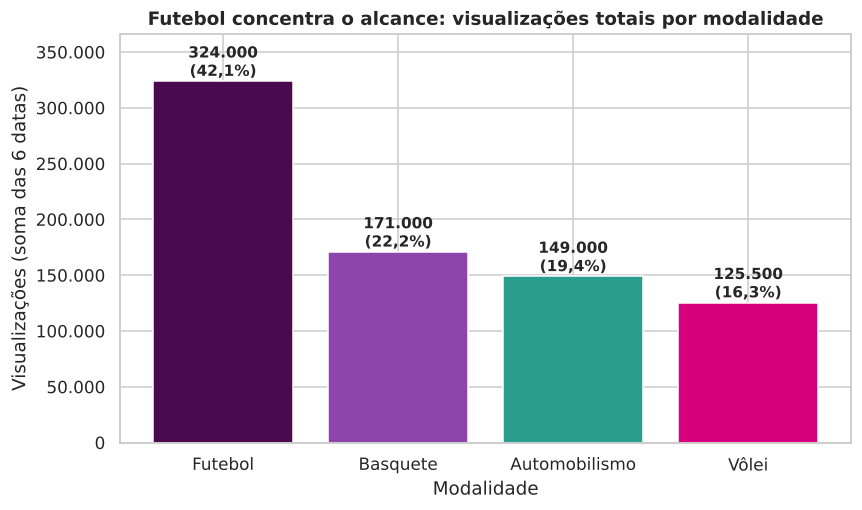

In [12]:
# ---------- Gráfico 1: visualizações por modalidade ----------
v_mod = por_modalidade["visualizacoes"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.8))
barras = ax.bar(v_mod.index, v_mod.values, color=[CORES_MOD[m] for m in v_mod.index])
ax.set_title("Futebol concentra o alcance: visualizações totais por modalidade", fontsize=12, fontweight="bold")
ax.set_xlabel("Modalidade")
ax.set_ylabel("Visualizações (soma das 6 datas)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: br(x, 0)))
ax.set_ylim(0, v_mod.max() * 1.13)
for b, m in zip(barras, v_mod.index):
    pct = por_modalidade.loc[m, "participacao_views_pct"]
    ax.annotate(f"{br(b.get_height(), 0)}\n({br(pct, 1)}%)", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretação — Gráfico 1.** O Futebol reúne 324.000 visualizações (42,1% do total), mais que o dobro do Vôlei (125.500) e quase o dobro do Basquete (171.000). Isso mostra **onde está o alcance**, mas não onde está o valor: como veremos, o Futebol é a modalidade com menor RPM e menor conversão. Volume, sozinho, não indica relevância nem retorno.

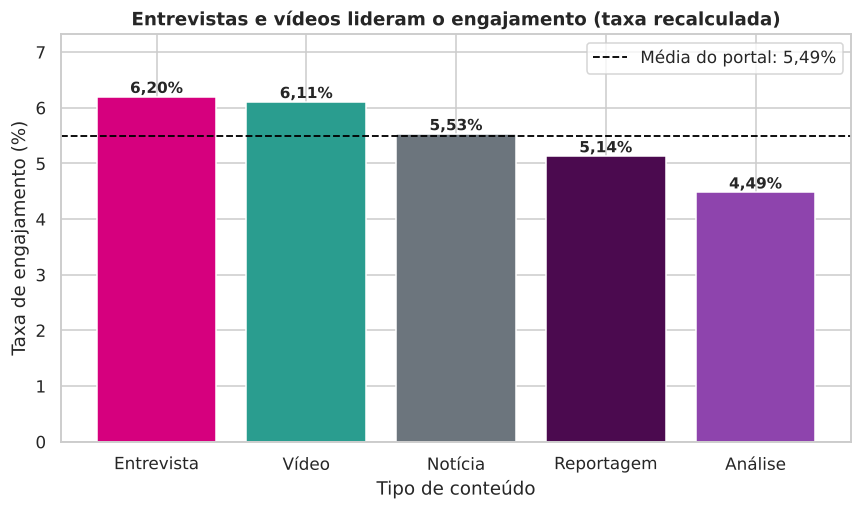

In [13]:
# ---------- Gráfico 2: taxa de engajamento por tipo de conteúdo ----------
eng_tipo = por_tipo["taxa_engajamento_pct"].sort_values(ascending=False)
eng_portal = dados["total_interacoes"].sum() / dados["visualizacoes"].sum() * 100   # referência: portal inteiro

fig, ax = plt.subplots(figsize=(8, 4.8))
barras = ax.bar(eng_tipo.index, eng_tipo.values, color=[CORES_TIPO[t] for t in eng_tipo.index])
ax.axhline(eng_portal, color="black", linestyle="--", linewidth=1.2, label=f"Média do portal: {br(eng_portal)}%")
ax.set_title("Entrevistas e vídeos lideram o engajamento (taxa recalculada)", fontsize=12, fontweight="bold")
ax.set_xlabel("Tipo de conteúdo")
ax.set_ylabel("Taxa de engajamento (%)")
ax.set_ylim(0, eng_tipo.max() * 1.18)
for b in barras:
    ax.annotate(f"{br(b.get_height())}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretação — Gráfico 2.** Entrevista (6,20%) e Vídeo (6,11%) ficam acima da média do portal (5,49%); Análise (4,49%) é a menor. A diferença entre os dois primeiros é pequena e cada formato tem só 4 a 6 publicações, então o ranking é **indicativo**, não definitivo. Formatos que dão voz a personagens e mostram a ação parecem estimular mais curtidas, comentários e compartilhamentos.

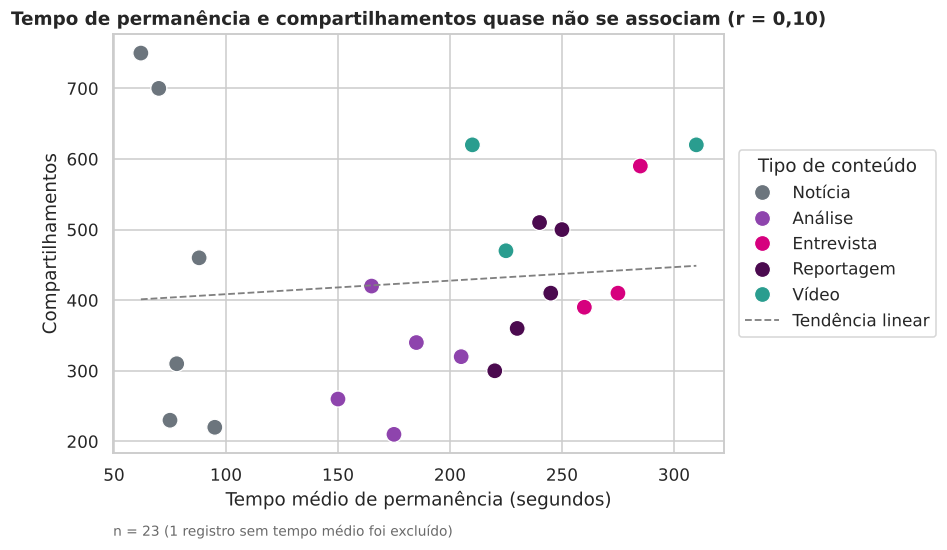

In [14]:
# ---------- Gráfico 3: dispersão entre tempo médio e compartilhamentos ----------
graf3 = dados.dropna(subset=["tempo_medio_segundos"])          # o registro ausente não entra no gráfico
r_pearson = graf3["tempo_medio_segundos"].corr(graf3["compartilhamentos"])

fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.scatterplot(data=graf3, x="tempo_medio_segundos", y="compartilhamentos", hue="tipo_conteudo",
                palette=CORES_TIPO, s=110, edgecolor="white", ax=ax)

# Reta de tendência (mínimos quadrados) apenas como guia visual
a, b = np.polyfit(graf3["tempo_medio_segundos"], graf3["compartilhamentos"], 1)
xs = np.linspace(graf3["tempo_medio_segundos"].min(), graf3["tempo_medio_segundos"].max(), 50)
ax.plot(xs, a * xs + b, color="gray", linestyle="--", linewidth=1.2, label="Tendência linear")

ax.set_title(f"Tempo de permanência e compartilhamentos quase não se associam (r = {br(r_pearson)})",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Tempo médio de permanência (segundos)")
ax.set_ylabel("Compartilhamentos")
ax.text(0.0, -0.17, f"n = {len(graf3)} (1 registro sem tempo médio foi excluído)", transform=ax.transAxes,
        fontsize=9, va="top", color="dimgray")
ax.legend(title="Tipo de conteúdo", loc="center left", bbox_to_anchor=(1.01, 0.5))   # legenda fora, sem cobrir pontos
plt.tight_layout()
plt.show()

**Interpretação — Gráfico 3.** A nuvem de pontos é dispersa e a reta é quase plana (r ≈ 0,10): **ficar mais tempo na página não se traduz, nesta base, em mais compartilhamentos**. Os pontos de maior tempo (vídeos e entrevistas) e os de menor tempo (notícias) alcançam níveis parecidos de compartilhamento, o que sugere que o ato de compartilhar depende mais do tema/emoção do que da profundidade da leitura. Com 23 pontos, é só um indício.

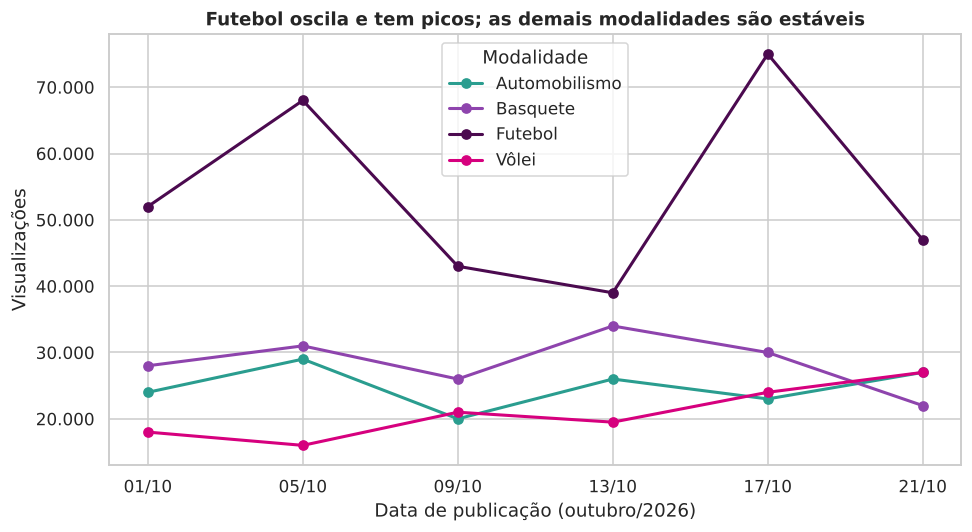

In [15]:
# ---------- Gráfico 4 (opcional): evolução das visualizações por modalidade ----------
evolucao = dados.pivot_table(index="data_publicacao", columns="modalidade", values="visualizacoes", aggfunc="sum")

fig, ax = plt.subplots(figsize=(9, 5))
for mod in evolucao.columns:
    ax.plot(evolucao.index, evolucao[mod], marker="o", linewidth=2, label=mod, color=CORES_MOD[mod])
ax.set_xticks(evolucao.index)
ax.set_xticklabels([d.strftime("%d/%m") for d in evolucao.index])
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: br(x, 0)))
ax.set_title("Futebol oscila e tem picos; as demais modalidades são estáveis", fontsize=12, fontweight="bold")
ax.set_xlabel("Data de publicação (outubro/2026)")
ax.set_ylabel("Visualizações")
ax.legend(title="Modalidade")
plt.tight_layout()
plt.show()

**Interpretação — Gráfico 4.** O Futebol varia entre 39.000 e 75.000 visualizações, com picos em 05/10 (vídeo de lances, 68.000) e 17/10 (post no Instagram, 75.000). As outras modalidades ficam entre 16.000 e 34.000. Há **uma publicação por modalidade em cada data**, então os picos refletem o conteúdo e o canal escolhidos — não a quantidade de publicações.

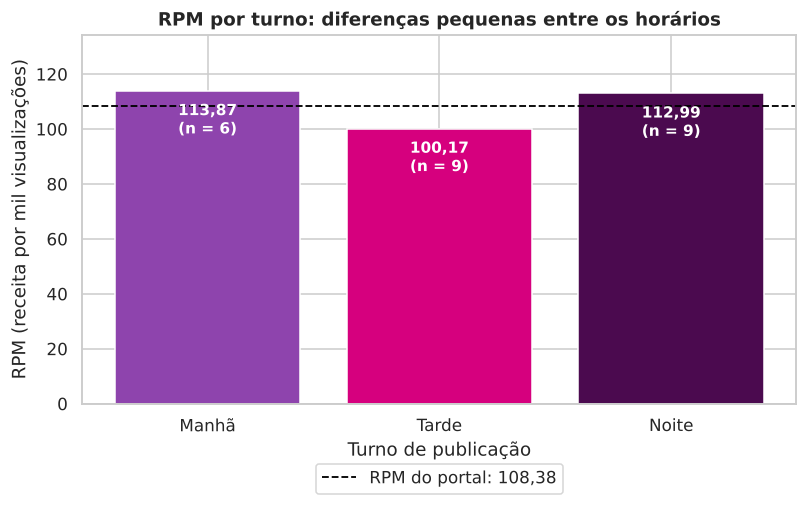

Turno x tipo de conteúdo (nº de publicações):


tipo_conteudo,Análise,Entrevista,Notícia,Reportagem,Vídeo
turno_publicacao,,,,,
Manhã,1,0,4,1,0
Noite,0,4,0,1,4
Tarde,4,0,2,3,0


Turno x portal (nº de publicações):


portal,Instagram,Newsletter,Site,YouTube
turno_publicacao,,,,
Manhã,0,2,4,0
Noite,0,0,1,8
Tarde,2,0,7,0


In [16]:
# ---------- Gráfico 5 (opcional): RPM por turno de publicação ----------
rpm_turno = por_turno["rpm"].reindex(["Manhã", "Tarde", "Noite"])
rpm_portal = dados["receita_publicitaria"].sum() / dados["visualizacoes"].sum() * 1000

fig, ax = plt.subplots(figsize=(7.5, 4.8))
barras = ax.bar(rpm_turno.index, rpm_turno.values, color=["#8E44AD", "#D6007E", "#4B0A4F"])
ax.axhline(rpm_portal, color="black", linestyle="--", linewidth=1.2, label=f"RPM do portal: {br(rpm_portal)}")
ax.set_title("RPM por turno: diferenças pequenas entre os horários", fontsize=12, fontweight="bold")
ax.set_xlabel("Turno de publicação")
ax.set_ylabel("RPM (receita por mil visualizações)")
ax.set_ylim(0, rpm_turno.max() * 1.18)
for b, t in zip(barras, rpm_turno.index):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() - 4,       # rótulo dentro da barra (a linha de referência não o cobre)
            f"{br(b.get_height())}\n(n = {int(por_turno.loc[t, 'publicacoes'])})",
            ha="center", va="top", fontsize=10, fontweight="bold", color="white")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
plt.show()

# Turno está "misturado" com formato e canal? Tabelas cruzadas:
print("Turno x tipo de conteúdo (nº de publicações):")
display(pd.crosstab(dados["turno_publicacao"], dados["tipo_conteudo"]))
print("Turno x portal (nº de publicações):")
display(pd.crosstab(dados["turno_publicacao"], dados["portal"]))

**Interpretação — Gráfico 5.** Manhã (113,87) e Noite (112,99) têm RPM praticamente iguais, e a Tarde (100,17) fica ~8% abaixo da média do portal (108,38). **Não dá para atribuir isso ao horário:** as tabelas cruzadas mostram que a Noite reúne 4 entrevistas, 4 vídeos e 8 de 9 publicações no YouTube, e a Manhã concentra 4 das 6 notícias. Turno, formato e canal estão **confundidos** — recomendar "publicar à noite" com esses dados seria um erro.

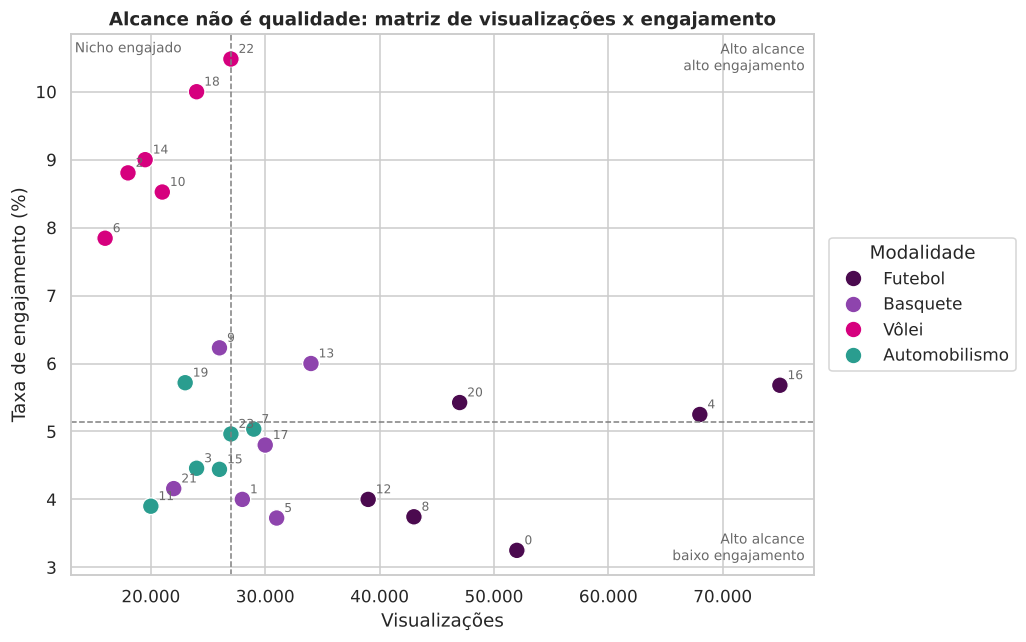

In [17]:
# ---------- Gráfico 6 (extra, visão de marketing): matriz alcance x engajamento ----------
med_views = dados["visualizacoes"].median()
med_eng   = dados["taxa_engajamento_pct"].median()

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.scatterplot(data=dados, x="visualizacoes", y="taxa_engajamento_pct", hue="modalidade",
                palette=CORES_MOD, s=120, edgecolor="white", ax=ax)
ax.axvline(med_views, color="gray", linestyle="--", linewidth=1)
ax.axhline(med_eng,   color="gray", linestyle="--", linewidth=1)
for i, r in dados.iterrows():                      # número da linha para identificar cada ponto
    ax.annotate(str(i), (r["visualizacoes"], r["taxa_engajamento_pct"]), xytext=(5, 4),
                textcoords="offset points", fontsize=8, color="dimgray")

x_max, y_max = ax.get_xlim()[1], ax.get_ylim()[1]
ax.text(x_max * 0.99, y_max * 0.99, "Alto alcance\nalto engajamento", ha="right", va="top", fontsize=9, color="dimgray")
ax.text(x_max * 0.99, ax.get_ylim()[0] + 0.15, "Alto alcance\nbaixo engajamento", ha="right", va="bottom", fontsize=9, color="dimgray")
ax.text(ax.get_xlim()[0] + 300, y_max * 0.99, "Nicho engajado", ha="left", va="top", fontsize=9, color="dimgray")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: br(x, 0)))
ax.set_title("Alcance não é qualidade: matriz de visualizações x engajamento", fontsize=12, fontweight="bold")
ax.set_xlabel("Visualizações")
ax.set_ylabel("Taxa de engajamento (%)")
ax.legend(title="Modalidade", loc="center left", bbox_to_anchor=(1.01, 0.5))   # legenda fora do gráfico
plt.tight_layout()
plt.show()

**Interpretação — Gráfico 6.** As linhas tracejadas marcam as medianas (27.000 visualizações; 5,14% de engajamento). Os seis conteúdos de Futebol ficam todos à direita (39.000 a 75.000 visualizações), mas com engajamento entre 3,25% e 5,68%; os seis de Vôlei ficam à esquerda da mediana (um deles exatamente sobre ela) e no alto (7,84% a 10,48%). **Maior alcance não vem acompanhado de maior engajamento** — a relação é, no máximo, inversa nesta amostra.

### Questão 4 — Comparação entre alcance e qualidade

In [18]:
# Alto alcance = 25% mais vistos; menor alcance = abaixo da mediana de visualizações
limite_alto = dados["visualizacoes"].quantile(0.75)
mediana_v   = dados["visualizacoes"].median()
cols = ["titulo", "modalidade", "tipo_conteudo", "portal", "turno_publicacao", "visualizacoes",
        "taxa_engajamento_pct", "tempo_medio_segundos", "taxa_recirculacao_pct", "rpm"]

alto_alcance  = dados[dados["visualizacoes"] >= limite_alto].nsmallest(1, "taxa_engajamento_pct")
menor_alcance = dados[dados["visualizacoes"] <  mediana_v].nlargest(1, "taxa_engajamento_pct")

print(f"Corte de alto alcance (percentil 75): {br(limite_alto, 0)} visualizações | mediana: {br(mediana_v, 0)}")
print("\n>> Alto alcance e BAIXO engajamento:")
display(alto_alcance[cols].round(2))
print(">> Menor alcance e MAIOR engajamento:")
display(menor_alcance[cols].round(2))

Corte de alto alcance (percentil 75): 35.250 visualizações | mediana: 27.000

>> Alto alcance e BAIXO engajamento:


,titulo,modalidade,tipo_conteudo,portal,turno_publicacao,visualizacoes,taxa_engajamento_pct,tempo_medio_segundos,taxa_recirculacao_pct,rpm
0,Clássico nacional movimenta a rodada,Futebol,Notícia,Site,Manhã,52000,3.25,78.0,7.88,82.69


>> Menor alcance e MAIOR engajamento:


,titulo,modalidade,tipo_conteudo,portal,turno_publicacao,visualizacoes,taxa_engajamento_pct,tempo_medio_segundos,taxa_recirculacao_pct,rpm
18,Rali mais longo da partida em detalhes,Vôlei,Vídeo,YouTube,Noite,24000,10.0,310.0,10.83,133.33


**Resultado**
- **Alto alcance, baixo engajamento:** *"Clássico nacional movimenta a rodada"* (Futebol, Notícia, Site) — 52.000 visualizações, mas apenas **3,25%** de engajamento e 78 s de permanência.
- **Menor alcance, maior engajamento:** *"Rali mais longo da partida em detalhes"* (Vôlei, Vídeo, YouTube) — 24.000 visualizações e **10,00%** de engajamento, com 310 s de permanência (a maior da base).

**Hipótese (não comprovada) para a diferença:** o primeiro é uma **notícia de grande apelo**, que atrai um público amplo e "de passagem" — lê o resultado, sente-se informado e sai, sem motivo para reagir. O segundo é um **vídeo de nicho**, voltado a um público que já tem vínculo com a modalidade e que **reage e compartilha** o lance que viu. Outras explicações possíveis: efeito do canal (YouTube tem botões de interação mais visíveis), do formato (vídeo longo) ou do tamanho da audiência. Para testar a hipótese seria preciso comparar conteúdos **do mesmo formato e canal** com públicos de tamanhos diferentes.

### Questão 5 — Associação entre variáveis

In [19]:
from scipy import stats

# --- Par 1: tempo médio x compartilhamentos (23 pares; o ausente é descartado) ---
par1 = dados[["tempo_medio_segundos", "compartilhamentos"]].dropna()
r1, p1 = stats.pearsonr(par1["tempo_medio_segundos"], par1["compartilhamentos"])
s1, ps1 = stats.spearmanr(par1["tempo_medio_segundos"], par1["compartilhamentos"])

# --- Par 2: visualizações x novos assinantes (24 pares) ---
par2 = dados[["visualizacoes", "novos_assinantes"]]
r2, p2 = stats.pearsonr(par2["visualizacoes"], par2["novos_assinantes"])
s2, ps2 = stats.spearmanr(par2["visualizacoes"], par2["novos_assinantes"])

# Teste de robustez: remove o ponto de maior alcance (post de Futebol no Instagram, linha 16)
sem_outlier = dados.drop(index=dados["visualizacoes"].idxmax())
r2b, p2b = stats.pearsonr(sem_outlier["visualizacoes"], sem_outlier["novos_assinantes"])

resultado = pd.DataFrame({
    "par": ["tempo médio x compartilhamentos", "visualizações x novos assinantes",
            "visualizações x novos assinantes (sem o maior alcance)"],
    "n": [len(par1), len(par2), len(sem_outlier)],
    "pearson_r": [r1, r2, r2b],
    "p_valor": [p1, p2, p2b],
    "spearman_rho": [s1, s2, np.nan],
})
display(resultado.round(3))

,par,n,pearson_r,p_valor,spearman_rho
0,tempo médio x compartilhamentos,23,0.098,0.657,0.217
1,visualizações x novos assinantes,24,0.547,0.006,0.565
2,visualizações x novos assinantes (sem o maior alcance),23,0.704,0.000,NaN


**Leitura dos números**
- **Tempo médio × compartilhamentos:** r ≈ **0,10** (p ≈ 0,66; Spearman ≈ 0,22) — associação **muito fraca e não distinguível de zero** com 23 pares.
- **Visualizações × novos assinantes:** r ≈ **0,55** (p ≈ 0,006; Spearman ≈ 0,57) — associação **moderada e positiva**. Sem o ponto de maior alcance (Instagram), sobe para ≈ 0,70: ele "enfraquece" a relação porque trouxe muita audiência e poucos assinantes.

**Por que correlação positiva não comprova causalidade?**
1. **Terceira variável (confusão):** o *tamanho do evento* ou da modalidade pode elevar, ao mesmo tempo, visualizações e assinaturas. Um clássico decisivo atrai mais gente **e** mais interessados em assinar; as duas variáveis sobem juntas sem que uma cause a outra.
2. **Escala:** conteúdos maiores tendem a ter mais de tudo (cliques, interações, assinaturas). Por isso é mais informativo olhar **assinantes por mil visualizações**: o Futebol tem o maior volume absoluto e a menor taxa (3,0), contra 5,5 do Vôlei.
3. **Sentido da relação:** assinantes podem voltar e aumentar as visualizações, e não o contrário.
4. **Amostra pequena e pouco diversa:** 24 publicações em 6 datas permitem coincidências; a correlação descreve **associação nesta amostra**, não o efeito de uma decisão editorial. Só um **experimento** (teste A/B) permite falar em causa.

### Questão 6 — Insights editoriais
*(evidência numérica → interpretação jornalística → relevância editorial)*

**Insight 1 — O maior alcance não é o maior retorno**
- **Evidência:** o Futebol concentra **42,1%** das visualizações (324.000), mas tem o **menor RPM (81,79 vs. 108,38 do portal)**, a **menor recirculação (7,96%)** e a **menor conversão (3,78%)**; gera **3,0 assinantes por mil visualizações**, contra **5,5 do Vôlei** e **5,3 do Automobilismo**.
- **Interpretação jornalística:** o futebol atrai um público amplo e de consumo rápido (resultado, lance, polêmica); vôlei e automobilismo têm públicos menores, porém mais envolvidos e dispostos a se aprofundar.
- **Relevância editorial:** o Futebol cumpre o papel de **alcance e marca**; as modalidades de nicho podem cumprir o de **fidelização e assinatura**. Cortar ou reduzir uma modalidade por ter poucas visualizações seria um erro — e também a diversidade de cobertura é um critério jornalístico, não só comercial.

**Insight 2 — Notícia rápida e conteúdo aprofundado têm funções diferentes**
- **Evidência:** a Notícia tem **78 s** de permanência, recirculação de **7,83%**, conversão de **3,79%** e RPM de **82,30**; a Reportagem tem **237 s**, **10,00%**, **4,90%** e **136,92**. A Entrevista (3 registros com tempo) chega a **~273 s**, com conversão de 4,77% e RPM de 123,68.
- **Interpretação jornalística:** a notícia informa depressa e traz tráfego; a reportagem e a entrevista retêm, contextualizam e geram valor por leitor.
- **Relevância editorial:** os formatos **não devem ser julgados pelas mesmas métricas**. Notícia: alcance, velocidade e recirculação; reportagem/entrevista: tempo, conversão e RPM. Medir tudo com "visualizações" favoreceria sempre o conteúdo mais superficial.

**Insight 3 — O canal define o papel do conteúdo: Instagram é vitrine, Newsletter é fidelização**
- **Evidência:** o Instagram trouxe **102.000 visualizações** (13,3% do total) em 2 publicações, com o **maior engajamento entre os canais (6,95%)**, mas o **menor tempo (66 s)**, a **menor conversão (3,24%)**, o **menor RPM (60,78)** e **2,3 assinantes por mil visualizações**. A Newsletter, com 42.000 visualizações em 2 publicações, tem **RPM 142,86** e conversão de **4,71%**.
- **Interpretação jornalística:** curtir e compartilhar no Instagram é uma interação **rápida e superficial**, que não atravessa o funil até a leitura aprofundada e a assinatura; a newsletter fala com um leitor que já escolheu receber o conteúdo.
- **Relevância editorial:** usar o Instagram como **porta de entrada**, com chamadas para conteúdos mais profundos, e a newsletter como canal de relacionamento. *Cautela:* são apenas 2 publicações por canal.

### Questão 7 — Recomendações

**Recomendação 1 — Transformar picos de alcance do Futebol em recirculação**
- **Ação proposta:** inserir, nas notícias de Futebol e nos posts de Instagram, um bloco "Aprofunde" que leve a uma reportagem, entrevista ou vídeo relacionado (do mesmo jogo, time ou tema).
- **Evidência:** Futebol tem a menor recirculação (7,96% vs. 9,00% do portal) e a menor conversão (3,78%); a notícia de Futebol no Instagram tem recirculação de 6,40% e RPM de 48,00, os menores da base.
- **Resultado esperado:** levar a recirculação do Futebol, no mínimo, à média do portal (~9%) e aumentar os assinantes por mil visualizações, **sem queda de alcance**.
- **Métrica de acompanhamento:** taxa de recirculação, taxa de conversão e assinantes por mil visualizações das notícias de Futebol; como métrica de controle, as próprias visualizações.
- **Forma de validação:** **teste A/B de 4 semanas** — metade das notícias de Futebol com o bloco e metade sem, sorteadas, mesmo turno e canal; comparar as proporções com teste estatístico e verificar se o alcance se manteve.

**Recomendação 2 — Piloto de aprofundamento em Vôlei e Automobilismo**
- **Ação proposta:** por 4 semanas, ampliar reportagens, entrevistas e vídeos nessas duas modalidades (YouTube e Site), mantendo a cobertura factual e a de Futebol, e priorizando **pautas de interesse público e relevância esportiva**, não apenas as de maior apelo.
- **Evidência:** Vôlei tem engajamento de 9,25% e conversão de 5,34%; Automobilismo tem RPM de 163,76 e recirculação de 10,81%; a Reportagem tem RPM de 136,92 e conversão de 4,90%.
- **Resultado esperado:** manter acima de 5 os assinantes por mil visualizações e acima de ~120 o RPM nessas modalidades, ampliando o volume de publicações.
- **Métrica de acompanhamento:** assinantes por mil visualizações, RPM, taxa de conversão e taxa de engajamento por modalidade e formato.
- **Forma de validação:** comparar com a linha de base atual (6 publicações por modalidade) e com um grupo de controle (Basquete) no mesmo período; **ampliar a amostra** antes de generalizar e acompanhar a variação entre publicações para separar efeito de formato, canal e tema.

### Questão 8 — Limitações e dados adicionais necessários

**Limitações da análise**
- **Amostra pequena e curta:** 24 publicações, 6 datas e 4 a 6 publicações por formato/modalidade; um único caso altera as médias. Resultados são **indícios**, não conclusões estatísticas.
- **Variáveis confundidas:** turno, formato e canal andam juntos (a Noite é quase toda YouTube; a Manhã é majoritariamente notícia), o que impede isolar o efeito de cada um.
- **Valor ausente:** o tempo médio de uma entrevista não foi registrado; a média desse formato usa 3 de 4 publicações.
- **"Retenção" medida só pelo tempo médio** e a **frequência média** varia pouco (1,17 a 1,26), então ela não diferencia conteúdos.
- **Relevância jornalística não está nos dados:** os números não dizem se a pauta era de interesse público, exclusiva, precisa ou diversa.

**Dados adicionais necessários**
1. **Custo e tempo de produção** (horas de redação/edição, equipe) para calcular retorno por pauta.
2. **Perfil e origem da audiência:** público novo × recorrente, assinantes × não assinantes, região, dispositivo e fonte de tráfego (busca, rede social, direto, newsletter).
3. **Contexto editorial e esportivo:** se houve evento decisivo (final, clássico, convocação) e se o conteúdo foi impulsionado ou recebeu destaque na home.
4. **Série histórica mais longa** (meses, não 3 semanas) e mais publicações por categoria.
5. **Retenção real:** percentual lido/assistido, taxa de rejeição, retorno do usuário e **cancelamento (churn) dos assinantes** gerados.
6. **Qualidade jornalística:** avaliação editorial de relevância, diversidade de fontes e checagem.

## Conclusão

A análise de 24 publicações mostra que alcance, engajamento e conversão seguem caminhos diferentes. O Futebol concentra 42,1% das visualizações, mas apresenta o menor RPM (81,79) e a menor conversão (3,78%), enquanto o Vôlei, com 16,3% do alcance, lidera em engajamento (9,25%) e conversão (5,34%). Entrevistas, reportagens e vídeos retêm mais o leitor do que notícias rápidas, que cumprem outro papel e não devem ser avaliadas pelas mesmas métricas. A correlação entre visualizações e assinaturas (r = 0,55) não prova causalidade. Recomenda-se testar a recirculação no Futebol e ampliar formatos aprofundados, usando os dados como apoio, sem substituir critérios de relevância e interesse público.

In [20]:
# Verifica se a conclusão respeita o limite de 100 a 150 palavras
conclusao = (
    "A análise de 24 publicações mostra que alcance, engajamento e conversão seguem caminhos diferentes. O Futebol concentra 42,1% das visualizações, mas apresenta o menor RPM (81,79) e a menor conversão (3,78%), enquanto o Vôlei, com 16,3% do alcance, lidera em engajamento (9,25%) e conversão (5,34%). Entrevistas, reportagens e vídeos retêm mais o leitor do que notícias rápidas, que cumprem outro papel e não devem ser avaliadas pelas mesmas métricas. A correlação entre visualizações e assinaturas (r = 0,55) não prova causalidade. Recomenda-se testar a recirculação no Futebol e ampliar formatos aprofundados, usando os dados como apoio, sem substituir critérios de relevância e interesse público."
)
n_palavras = len(conclusao.split())
print("Palavras na conclusão:", n_palavras, "->", "OK (entre 100 e 150)" if 100 <= n_palavras <= 150 else "FORA DO LIMITE")

Palavras na conclusão: 104 -> OK (entre 100 e 150)


## Discussão de fechamento

**O conteúdo mais visualizado também foi o mais relevante?** Não. O mais visto (post de Futebol no Instagram, 75.000 visualizações) tem o menor RPM e a menor conversão da base. Já o que mais gerou assinaturas foi um vídeo de Futebol (190). Relevância jornalística depende de interesse público, precisão e contexto, que os dados de audiência não medem.

**Como a modalidade influencia a audiência?** Muito no volume (Futebol = 42,1% das visualizações), pouco no engajamento (exceto Vôlei, com 9,25%) e de forma diferente na monetização (Automobilismo, RPM 163,76).

**Notícias rápidas e reportagens devem ser avaliadas pelas mesmas métricas?** Não. A notícia vale por velocidade e alcance (78 s de permanência); a reportagem vale por profundidade, retenção e conversão (237 s, RPM 136,92). KPIs diferentes para finalidades diferentes.

**Um conteúdo com poucas visualizações pode ter alto valor jornalístico?** Sim: uma pauta de interesse público, de modalidade pouco coberta ou de representatividade tende a ter nicho pequeno, e seu valor não se reduz ao tráfego. O Vôlei, com menos alcance, é o que mais engaja e converte.

**Quais riscos surgem quando decisões editoriais são orientadas só por cliques?** Sensacionalismo e *clickbait*, empobrecimento da pauta, abandono de modalidades e temas de menor audiência, perda de diversidade e de confiança do público, e leitura equivocada de correlações como causas.

**Como equilibrar interesse público, qualidade jornalística e desempenho digital?** Definir métricas por finalidade do conteúdo, reservar espaço de pauta que não dependa de audiência, usar testes controlados antes de mudar a estratégia e deixar a decisão final com critérios editoriais.

> **Os dados devem apoiar a decisão editorial, mas não substituir os critérios jornalísticos de relevância, interesse público, diversidade, precisão e responsabilidade.**